# 10 — Intraday forecasting: rules, corrections, controls and daily pairings

**The preferred main research pairing is tuned daily LightGBM plus an annual 15:30 ridge correction.** It achieves development log RMSE **0.45471** and stock WAPE **33.98%** on the matched regular-session universe, with **0.40418** log RMSE in previously inspected 2025. The neural-blend pairing has a slightly lower point estimate, but an uncertain incremental gain and more complexity.

This notebook completes **Checkpoint 6**. It follows the historical ratio rule through noon and 15:30 ridge/LightGBM updates, matched daily-only controls, feature ablation, partial correction, frozen-forecast inference, quarterly refits and the daily-anchor comparison.

Some original large forecast/sample files are absent from this checkout. Saved fitted parameters remain. Here we rebuild the corrected noon input panel from raw aggregates, restore the original forecasts and the later ridge variants, verify their reported metrics, reconstruct saved pairing coefficients, and perform a fresh 2022 ridge worked fit. Full multi-year fitting is not rerun. Source uncertainty tables remain labelled as saved calculations, with point estimates checked.

The earlier control/ablation/shrinkage/quarterly studies use the **original 58-source daily LightGBM**. The final pairing study explicitly tests the **tuned 61-source daily champion**. Improvements from those earlier studies cannot simply be added to the tuned pairing. The 2025 year is retrospective confirmation throughout.

New audit artifacts are saved under `outputs/experiments/32_intraday_master_audit`. Notebook 11's dynamic and Kalman exploration starts after this checkpoint is approved.

In [1]:
from pathlib import Path
import sys,os,json,hashlib,gc,tempfile,importlib.metadata
from datetime import datetime,timezone
import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
from IPython.display import display
ROOT=next(p for p in [Path.cwd().resolve(),*Path.cwd().resolve().parents] if (p/'blackrock_data').is_dir())
sys.path.insert(0,str(ROOT))
from notebooks.modeling_utils import fit_preprocessor,apply_preprocessor,fit_ridge,predict_ridge
from notebooks import build_intraday_1530_update as intraday
from notebooks import shrink_intraday_ridge_update as shrink
E=ROOT/'outputs/experiments';A=E/'27_intraday_anchor_comparison';RUN=E/'32_intraday_master_audit'
for directory in [RUN,RUN/'predictions',RUN/'fresh_ridge_2022']:directory.mkdir(parents=True,exist_ok=True)
PANEL=next(p for p in [ROOT/'outputs/reproduction/01_daily_panel/enriched_daily_panel.parquet',
    ROOT/'outputs/eda/05_feature_engineering/enriched_daily_panel.parquet',
    ROOT/'midterm presentation/data_analysis/cache/enriched_daily_panel.parquet'] if p.is_file())
work=tempfile.TemporaryDirectory(prefix='auction-intraday-master-')
con=duckdb.connect(config={'threads':4,'memory_limit':'2GB','temp_directory':work.name})
YEARS=[2022,2023,2024,2025];DEV=[2022,2023,2024]
SOURCES={19:E/'19_intraday_1530',20:E/'20_intraday_noon',21:E/'21_intraday_robustness',22:E/'22_intraday_ridge_control',
         23:E/'23_intraday_feature_ablation',24:E/'24_intraday_shrinkage',25:E/'25_frozen_intraday_evaluation',26:E/'26_quarterly_intraday_audit',27:A}
pd.set_option('display.max_rows',65);pd.set_option('display.max_columns',14)
pd.set_option('display.float_format',lambda x:f'{x:,.6f}')
sns.set_theme(style='whitegrid',palette='colorblind');plt.rcParams.update({'figure.dpi':110})
inputs=set()
def read(study,name):
    path=SOURCES[study]/name;inputs.add(path);return pd.read_csv(path)
def load_json(path):inputs.add(path);return json.loads(path.read_text())
def sha(path):
    h=hashlib.sha256()
    with path.open('rb') as f:
        for chunk in iter(lambda:f.read(8*1024*1024),b''):h.update(chunk)
    return h.hexdigest()
def progress(message):
    line=f'{datetime.now(timezone.utc).isoformat()} {message}';print(line,flush=True)
    with (RUN/'progress.log').open('a') as f:f.write(line+'\n')
def save_frame(frame,path):
    temporary=path.with_suffix('.partial');temporary.unlink(missing_ok=True)
    con.register('audit_output',frame)
    try:con.execute('COPY audit_output TO ? (FORMAT PARQUET,COMPRESSION ZSTD)',[str(temporary)])
    finally:con.unregister('audit_output')
    temporary.replace(path)
def types(prep):return tuple(list(prep[key]) for key in ['continuous','boolean','categorical'])
def transform(frame,prep):return apply_preprocessor(frame,prep,*types(prep))
def scores(actual,pred):
    y=np.asarray(actual,float);p=np.asarray(pred,float)
    assert np.isfinite(y).all() and np.isfinite(p).all() and (p>=0).all()
    return {'observations':len(y),'rmse_log':np.sqrt(np.mean((np.log1p(y)-np.log1p(p))**2)),
            'wape':np.abs(y-p).sum()/y.sum(),'aggregate_bias':p.sum()/y.sum()-1}
def correction(frame,component,bounds):
    daily=frame.daily_forecast.to_numpy(float)
    fitted=np.maximum(np.expm1(np.clip(np.log1p(daily)+component,*bounds)),0)
    return np.where(frame.cp_available,fitted,daily)
versions={p:importlib.metadata.version(p) for p in ['lightgbm','numpy','pandas','duckdb']}
plan={'version':1,'panel_hash':sha(PANEL),'checkpoint_panel_hash':sha(A/'checkpoint_panel.parquet'),
      'versions':versions,'years':YEARS,'fresh_fit_year':2022,
      'raw_checkpoint_hashes':{str(p.relative_to(ROOT)):sha(p) for p in sorted((ROOT/'blackrock_data/stock_intraday/trade_checkpoints').glob('year=*/*.parquet'))},
      'original_daily_hashes':{p.name:sha(p) for p in sorted(A.glob('original_*.parquet'))},
      'source_hashes':{p.name:sha(p) for p in [ROOT/'notebooks/build_intraday_1530_update.py',ROOT/'notebooks/build_intraday_noon_update.py',
        ROOT/'notebooks/modeling_utils.py',ROOT/'notebooks/compare_intraday_anchors.py']}}
if (RUN/'plan.json').is_file():assert load_json(RUN/'plan.json')==plan
else:(RUN/'plan.json').write_text(json.dumps(plan,indent=2))
display(pd.Series(versions,name='execution version').to_frame())

,execution version
lightgbm,4.6.0
numpy,2.4.6
pandas,3.1.1
duckdb,1.5.6


## Forecasting logic and information timing

The daily anchor $D_t$ uses the preceding close's information. At checkpoint c, the correction target is

$$z_{t,c}=\log(1+A_t)-\log(1+D_t),\qquad
\hat A_{t,c}=\exp\{\operatorname{clip}[\log(1+D_t)+\hat z_{t,c}]\}-1.$$

Training-only bounds use historical 0.1% and 99.9% log-auction quantiles. Missing or invalid checkpoints retain **the exact daily forecast**, including its original bounds. Early-close sessions are excluded at both times to retain a common comparison universe; 15:30 would occur after their auction. This experiment therefore does not establish noon performance on early closes.

The simple ratio rule uses current cumulative checkpoint volume times the prior-20-stock-row median auction/checkpoint ratio. Missing ratio history uses a historical fitting-sample median ratio. It can respond to today's activity, but assumes a relatively stable relationship between trading by that time and closing-auction volume. The learned corrections can condition that relationship on more information.

| Sources | Count | Information available |
| --- | ---: | --- |
| Original daily features | 58 | Prior stock history and known calendar |
| Log daily forecast and historical checkpoint/price summaries | 5 | Prior close; shared with learned daily-only controls |
| Current cumulative volume/dollar volume/trades, recent activity, VWAP and normalisations | 10 | At the chosen checkpoint |
| Full original correction specification | 73 | Above sources combined |

Current final daily volume, closing price/return, auction shares and future checkpoints are excluded from model inputs. Label columns may exist in a data frame for scoring but are never included in the feature matrices. Aggregate source files do not contain underlying tick timestamps, so we can check their flags, dates and feature construction, but cannot independently re-audit the tick cutoff.

In [2]:
assert len(intraday.DAILY_FEATURES)==58 and len(intraday.CONTROL_FEATURES)==63 and len(intraday.MODEL_FEATURES)==73
assert set(intraday.INTRADAY_FEATURES).isdisjoint(intraday.CONTROL_FEATURES)
assert not set(intraday.MODEL_FEATURES)&{'auction_volume','log1p_auction_volume','current_daily_volume','current_close','current_return','auction_price'}
display(read(19,'feature_timing_catalog.csv').tail(15))
coverage=[]
for study,time in [(20,'12:00'),(19,'15:30')]:
    part=read(study,'coverage_by_year.csv');part=part[part.year.isin(YEARS)].copy()
    part['checkpoint']=time;part['valid_fraction']=part.valid_checkpoint_rows/part.regular_session_rows;coverage.append(part)
coverage=pd.concat(coverage,ignore_index=True)
assert coverage.groupby('checkpoint').regular_session_rows.sum().eq(1260168).all()
display(coverage[['checkpoint','year','eligible_targets','early_close_rows','regular_session_rows','valid_checkpoint_rows','daily_fallback_rows','valid_fraction']])

,feature,information_time
58,log_daily_forecast,saved out-of-time daily prediction using prior...
59,checkpoint_avg_volume20,prior close; historical checkpoint normalizati...
60,checkpoint_avg_trades20,prior close; historical checkpoint normalizati...
61,ratio20_auction_to_checkpoint,prior close; historical checkpoint normalizati...
62,lag1_price,prior close; historical checkpoint normalizati...
63,cp_cum_volume,observed by 15:30; normalization uses prior-on...
64,cp_cum_dollar_volume,observed by 15:30; normalization uses prior-on...
65,cp_cum_trade_count,observed by 15:30; normalization uses prior-on...
66,cp_recent_30m_volume,observed by 15:30; normalization uses prior-on...
67,cp_vwap,observed by 15:30; normalization uses prior-on...


,checkpoint,year,eligible_targets,early_close_rows,regular_session_rows,valid_checkpoint_rows,daily_fallback_rows,valid_fraction
0,12:00,2022,328634,1279,327355,326861,494,0.998491
1,12:00,2023,318679,2520,316159,315980,179,0.999434
2,12:00,2024,316212,3730,312482,312457,25,0.999920
3,12:00,2025,307853,3681,304172,304152,20,0.999934
4,15:30,2022,328634,1279,327355,327156,199,0.999392
5,15:30,2023,318679,2520,316159,316091,68,0.999785
6,15:30,2024,316212,3730,312482,312479,3,0.999990
7,15:30,2025,307853,3681,304172,304171,1,0.999997


## Honest stacked training and the reference universe

Corrections train on annually out-of-time daily forecasts from **2021 onward**, rather than fitted in-sample predictions from a daily model. For the 2022 update, tuning fits January–September 2021, validates October–December 2021 and refits on available 2021 history. Subsequent annual folds tune on history from 2021 before the previous full year, validate on that previous year and refit through it. Caps are 250,000 tuning, 120,000 validation and 350,000 refit rows, restricted to regular sessions with usable checkpoints for fitting. Evaluation includes every eligible regular-session row with exact daily fallback.

Ridge searches seven penalties from 1e−7 through 1e−1. The two LightGBM candidates share samples, preprocessing, search budget, residual target, bounds and the minimum-25-tree final-refit convention. Some daily-only controls selected fewer trees, so their final refit used 25; this affects interpretation of that control. The matched ridge control later isolates the checkpoint contribution within the ridge family.

The original daily reference scores about 0.46949 here, differing from its whole-universe daily score because early closes are excluded. The tuned daily anchor is only introduced in the later pairing comparison. Development metrics average annual 2022–2024 scores equally; 2025 is reported separately.

In [3]:
# Build a thin noon panel using the same shared feature SQL, with the corrected materialised join.
NOON=RUN/'noon_panel.parquet'
if not NOON.is_file():
    progress('Rebuilding noon inputs from raw checkpoint aggregates and out-of-time daily forecasts')
    paths=[str(A/f'original_{year}.parquet') for year in range(2021,2026)];inputs.update(map(Path,paths))
    con.read_parquet(paths).create_view('original_forecasts',replace=True)
    con.execute('CREATE TEMP VIEW daily_predictions AS SELECT date,permno,forecast AS daily_forecast FROM original_forecasts')
    query=intraday.checkpoint_panel_query(con,PANEL).replace('joined AS(','joined AS MATERIALIZED(')
    raw=ROOT/'blackrock_data/stock_intraday/trade_checkpoints/year=*/trade_checkpoints_*.parquet'
    con.execute(f"CREATE OR REPLACE TEMP VIEW raw_cp AS SELECT * FROM read_parquet('{raw}',union_by_name=true) WHERE checkpoint='12:00'")
    fields=list(dict.fromkeys(['date','permno','year','auction_volume','log1p_auction_volume','daily_forecast','cp_available','is_early_close',
        'size_percentile','liquidity_percentile',*intraday.MODEL_FEATURES]))
    projection=','.join('"'+name+'"' for name in fields)
    temporary=NOON.with_suffix('.partial');temporary.unlink(missing_ok=True)
    con.execute(f'COPY (SELECT {projection} FROM ({query})) TO ? (FORMAT PARQUET,COMPRESSION ZSTD)',[str(temporary)])
    temporary.replace(NOON)
for path,study in [(NOON,20),(A/'checkpoint_panel.parquet',19)]:
    inputs.add(path)
    counts=con.execute("SELECT year,count(*) AS eligible_targets,count(*) FILTER(WHERE is_early_close) AS early_close_rows,count(*) FILTER(WHERE NOT is_early_close) AS regular_session_rows,count(*) FILTER(WHERE NOT is_early_close AND cp_available) AS valid_checkpoint_rows FROM read_parquet(?) GROUP BY year ORDER BY year",[str(path)]).df()
    recorded=read(study,'coverage_by_year.csv')
    np.testing.assert_array_equal(counts,recorded[counts.columns])
print('Both panels reproduce saved yearly universe and checkpoint counts, including 2021 history.')

Both panels reproduce saved yearly universe and checkpoint counts, including 2021 history.


In [4]:
# Independently reproduce three prior-only checkpoint histories using pandas for 16 stocks.
stock_ids=con.execute('SELECT DISTINCT permno FROM read_parquet(?) ORDER BY permno LIMIT 16',[str(A/'checkpoint_panel.parquet')]).df().permno.tolist()
stock_list=','.join(map(str,stock_ids));history_checks=[]
for time,path in [('12:00',NOON),('15:30',A/'checkpoint_panel.parquet')]:
    raw=ROOT/'blackrock_data/stock_intraday/trade_checkpoints/year=*/trade_checkpoints_*.parquet'
    frame=con.execute(f"""SELECT p.date,p.permno,p.auction_volume,p.eligible_target,p.is_early_close,
        c.checkpoint_data_found,c.checkpoint_after_market_close,c.cum_volume,c.cum_trade_count
        FROM read_parquet('{PANEL}') p LEFT JOIN
        (SELECT * FROM read_parquet('{raw}',union_by_name=true) WHERE checkpoint='{time}') c USING(date,permno)
        WHERE p.permno IN ({stock_list}) ORDER BY p.permno,p.date""").df()
    available=frame.checkpoint_data_found.fillna(False)&~frame.checkpoint_after_market_close.fillna(True)&~frame.is_early_close.fillna(True)&frame.cum_volume.gt(0)
    frame['volume']=frame.cum_volume.where(available);frame['trades']=frame.cum_trade_count.where(available)
    frame['ratio']=(frame.auction_volume/frame.cum_volume).where(available&frame.eligible_target)
    for name,operation in [('volume','mean'),('trades','mean'),('ratio','median')]:
        frame['prior_'+name]=frame.groupby('permno')[name].transform(lambda s:getattr(s.shift(1).rolling(20,min_periods=1),operation)())
    saved=con.execute(f'SELECT date,permno,cp_available,checkpoint_avg_volume20,checkpoint_avg_trades20,ratio20_auction_to_checkpoint FROM read_parquet(?) WHERE permno IN ({stock_list})',[str(path)]).df()
    frame['independent_available']=available
    joined=frame.merge(saved,on=['date','permno'],validate='one_to_one')
    np.testing.assert_array_equal(joined.independent_available,joined.cp_available)
    for independent,stored in [('prior_volume','checkpoint_avg_volume20'),('prior_trades','checkpoint_avg_trades20'),('prior_ratio','ratio20_auction_to_checkpoint')]:
        np.testing.assert_allclose(joined[independent],joined[stored],equal_nan=True,rtol=1e-10,atol=1e-10)
    history_checks.append({'checkpoint':time,'stocks':len(stock_ids),'rows':len(joined),'features':3,'passed':True})
history_checks=pd.DataFrame(history_checks);history_checks.to_csv(RUN/'independent_history_checks.csv',index=False)
display(history_checks)

,checkpoint,stocks,rows,features,passed
0,12:00,16,16285,3,True
1,15:30,16,16285,3,True


## Restore and score the original forecasts and ridge variants

The next cell applies saved preprocessing and fitted parameters, with no model training. The ratio rule, ridge and two LightGBM forecasts are restored at both times. On the 15:30 panel we also restore daily-only ridge, eight feature ablations, four historically selected partial corrections and all sixteen quarterly ridge fits. Each reported annual score is checked against its source table; checkpoint-available scores are checked separately for the two original studies.

Partial corrections use the saved historical validation strengths. Quarterly fits use their own saved preprocessing and bounds. No group, strength or quarterly penalty is selected using evaluation labels in this reconstruction.

In [5]:
annual_sources={study:read(study,'annual_metrics.csv') for study in [19,20,22,23,24,26]}
verified=[]
def verify(study,year,name,pred,frame,sample=None):
    expected=annual_sources[study]
    year_col='year' if study==26 else 'test_year'
    expected=expected[(expected[year_col]==year)&expected.candidate.eq(name)]
    if sample is not None:expected=expected[expected['sample'].eq(sample)]
    assert len(expected)==1,(study,year,name,sample)
    result=scores(frame.auction_volume,pred)
    for key,value in result.items():np.testing.assert_allclose(value,expected.iloc[0][key],rtol=1e-8,atol=1e-9)
    verified.append({'study':study,'year':year,'candidate':name,'sample':sample or 'all_regular_sessions',**result})
projection=','.join('"'+f+'"' for f in dict.fromkeys(['date','permno','year','auction_volume','log1p_auction_volume','daily_forecast','cp_available',
    'size_percentile','liquidity_percentile',*intraday.MODEL_FEATURES]))
for study,time,path in [(19,'15:30',A/'checkpoint_panel.parquet'),(20,'12:00',NOON)]:
    for year in YEARS:
        progress(f'Restoring {time} forecasts and applicable variants for {year}')
        frame=con.execute(f'SELECT {projection} FROM read_parquet(?) WHERE year={year} AND NOT is_early_close ORDER BY date,permno',[str(path)]).df()
        assert not frame.duplicated(['date','permno']).any()
        labels=con.execute('SELECT date,permno,auction_volume FROM read_parquet(?) WHERE eligible_target AND NOT is_early_close AND year=? ORDER BY date,permno',[str(PANEL),year]).df()
        pd.testing.assert_frame_equal(frame[['date','permno','auction_volume']],labels,check_dtype=False)
        prep=load_json(SOURCES[study]/f'models/preprocessor_{year}.json')
        settings=load_json(SOURCES[study]/f'models/reconstruction_{year}.json')
        assert pd.Timestamp(settings['refit_end'])<frame.date.min()
        matrix=transform(frame,prep);available=frame.cp_available.to_numpy(bool)
        output=frame[['date','permno','year','auction_volume','cp_available']].copy()
        output['fixed_daily']=frame.daily_forecast
        ratio=frame.ratio20_auction_to_checkpoint.astype(float).fillna(settings['fallback_ratio']).to_numpy()
        rule=np.maximum(np.expm1(np.clip(np.log1p(frame.cp_cum_volume.to_numpy(float)*ratio),*settings['clip_log'])),0)
        output['checkpoint_ratio_rule']=np.where(available,rule,frame.daily_forecast)
        for name in ['ridge_update','lgbm_daily_control','lgbm_intraday_update']:
            names=load_json(SOURCES[study]/f'models/features_{name}_{year}.json')
            mask=[prep['output_names'].index(f) for f in names]
            if name=='ridge_update':
                model_path=SOURCES[study]/f'models/{name}_{year}.npy';inputs.add(model_path)
                component=predict_ridge(matrix[:,mask],np.load(model_path))
            else:
                model_path=SOURCES[study]/f'models/{name}_{year}.txt';inputs.add(model_path)
                component=lgb.Booster(model_file=str(model_path)).predict(matrix[:,mask],num_threads=4)
            output[name]=correction(frame,component,settings['clip_log'])
        for name in intraday.METHODS:
            np.testing.assert_array_equal(output.loc[~available,name],frame.loc[~available,'daily_forecast'])
            verify(study,year,name,output[name],frame,'all_regular_sessions')
            verify(study,year,name,output.loc[available,name],frame.loc[available],'checkpoint_available')
        if study==19:
            control_prep=load_json(SOURCES[22]/f'models/preprocessor_{year}.json')
            control=load_json(SOURCES[22]/f'models/reconstruction_{year}.json')
            xm=transform(frame,control_prep);mask=[control_prep['output_names'].index(f) for f in control['matrix_columns']]
            control_path=SOURCES[22]/f'models/ridge_daily_control_{year}.npy';inputs.add(control_path)
            output['ridge_daily_control']=correction(frame,predict_ridge(xm[:,mask],np.load(control_path)),control['clip_log'])
            for name in ['fixed_daily','ridge_update','ridge_daily_control']:verify(22,year,name,output[name],frame)
            ablation_prep=load_json(SOURCES[23]/f'models/preprocessor_{year}.json');xm=transform(frame,ablation_prep)
            for name in ['add_volume','add_trades','add_recent_activity','add_price','drop_volume','drop_trades','drop_recent_activity','drop_price']:
                saved=load_json(SOURCES[23]/f'models/{name}_{year}.json')
                assert pd.Timestamp(saved['refit_end'])<frame.date.min()
                mask=[ablation_prep['output_names'].index(f) for f in saved['matrix_columns']]
                model_path=SOURCES[23]/f'models/{name}_{year}.npy';inputs.add(model_path)
                output[name]=correction(frame,predict_ridge(xm[:,mask],np.load(model_path)),saved['clip_log'])
                verify(23,year,name,output[name],frame)
            for name in ['fixed_daily','ridge_update','ridge_daily_control']:verify(23,year,name,output[name],frame)
            strengths=read(24,'selected_strengths.csv');strengths=strengths[strengths.test_year.eq(year)]
            assert pd.to_datetime(strengths.validation_end).max()<frame.date.min()
            anchor=output.fixed_daily.to_numpy();full=output.ridge_update.to_numpy()
            np.testing.assert_array_equal(shrink.blend(anchor,full,0),anchor)
            np.testing.assert_array_equal(shrink.blend(anchor,full,1),full)
            for name in shrink.VARIANTS:
                alpha=np.ones(len(frame))
                for cell,mask in shrink.cells(frame,name).items():
                    alpha[mask]=strengths[strengths.candidate.eq(name)&strengths.cell.eq(cell)].alpha.item()
                output[name]=shrink.blend(anchor,full,alpha)
                assert (output[name]>=np.minimum(anchor,full)-1e-8).all() and (output[name]<=np.maximum(anchor,full)+1e-8).all()
                verify(24,year,name,output[name],frame)
            for name in ['fixed_daily','ridge_update']:verify(24,year,name,output[name],frame)
            output['quarterly_ridge']=np.nan
            for quarter in [1,2,3,4]:
                label=f'{year}Q{quarter}';mask=frame.date.dt.quarter.eq(quarter)
                qsettings=load_json(SOURCES[26]/f'models/reconstruction_{label}.json')
                qprep=load_json(SOURCES[26]/f'models/preprocessor_{label}.json')
                assert pd.Timestamp(qsettings['refit_dates'][1])<frame.loc[mask,'date'].min()
                qmodel=SOURCES[26]/f'models/quarterly_ridge_{label}.npy';inputs.add(qmodel)
                output.loc[mask,'quarterly_ridge']=correction(frame.loc[mask],predict_ridge(transform(frame.loc[mask],qprep),np.load(qmodel)),qsettings['clip_log'])
            for name,column in [('fixed_daily','fixed_daily'),('annual_ridge','ridge_update'),('quarterly_ridge','quarterly_ridge')]:verify(26,year,name,output[column],frame)
            for name in output.columns.difference(['date','permno','year','auction_volume','cp_available']):
                np.testing.assert_array_equal(output.loc[~available,name],frame.loc[~available,'daily_forecast'])
        save_frame(output,RUN/f'predictions/reconstructed_{study}_{year}.parquet')
        progress(f'Verified {len(output):,} common stock-days at {time}, {year}')
        del frame,matrix,output;gc.collect()
verified=pd.DataFrame(verified);verified.to_csv(RUN/'verified_annual_scores.csv',index=False)
assert len(verified)==172
print(f'All {len(verified)} source model/year/sample score rows match independently reconstructed forecasts.')

2026-11-18T16:55:22.105546+00:00 Restoring 15:30 forecasts and applicable variants for 2022


2026-11-18T16:55:34.055229+00:00 Verified 327,355 common stock-days at 15:30, 2022


2026-11-18T16:55:34.088436+00:00 Restoring 15:30 forecasts and applicable variants for 2023


2026-11-18T16:55:38.336328+00:00 Verified 316,159 common stock-days at 15:30, 2023


2026-11-18T16:55:38.363264+00:00 Restoring 15:30 forecasts and applicable variants for 2024


2026-11-18T16:55:43.207723+00:00 Verified 312,482 common stock-days at 15:30, 2024


... (7 outputs left out)

2026-11-18T16:56:02.197269+00:00 Verified 312,482 common stock-days at 12:00, 2024


2026-11-18T16:56:02.225004+00:00 Restoring 12:00 forecasts and applicable variants for 2025


2026-11-18T16:56:03.808153+00:00 Verified 304,172 common stock-days at 12:00, 2025


All 172 source model/year/sample score rows match independently reconstructed forecasts.


## Ratio rule, noon and 15:30: what changed?

The ratio rule is substantially worse than the unchanged daily anchor at both times. Current activity alone is insufficient without learning how its relevance varies across stocks and dates. Ridge has the lowest development error among the original five methods at both checkpoints. Noon ridge delivers about 51% of the 15:30 ridge's improvement over daily, making it a useful optional earlier estimate.

The original 15:30 LightGBM passes its incremental-information gate against the fixed daily anchor and learned daily-only LightGBM. Noon LightGBM beats its learned control but fails the complete gate against the fixed daily anchor: the mean improvement is too small and one year deteriorates beyond the limit. The matched ridge-only control below provides separate evidence for ridge's checkpoint information.

development_rmse_log  development_wape  \
checkpoint candidate                                                       
12:00      checkpoint_ratio_rule              0.762570          0.541024   
           fixed_daily                        0.469491          0.354676   
           lgbm_daily_control                 0.479021          0.359621   
           lgbm_intraday_update               0.469099          0.352445   
           ridge_update                       0.464589          0.348529   
15:30      checkpoint_ratio_rule              0.691529          0.492621   
           fixed_daily                        0.469491          0.354676   
           lgbm_daily_control                 0.478712          0.359470   
           lgbm_intraday_update               0.462146          0.347655   
           ridge_update                       0.459954          0.345919   

                                  development_bias  confirmation_rmse_log  \
checkpoint candidate                                                        
12:00      checkpoint_ratio_rule         -0.118642               0.688487   
           fixed_daily                   -0.144684               0.429014   
           lgbm_daily_control            -0.133428               0.429881   
           lgbm_intraday_update          -0.131024               0.421091   
           ridge_update                  -0.130164               0.416770   
15:30      checkpoint_ratio_rule         -0.156346               0.614224   
           fixed_daily                   -0.144684               0.429014   
           lgbm_daily_control            -0.133879               0.430338   
           lgbm_intraday_update          -0.119335               0.415594   
           ridge_update                  -0.118001               0.409157   

                                  confirmation_wape  confirmation_bias  
checkpoint candidate                                                    
12:00      checkpoint_ratio_rule           0.523167          -0.047689  
           fixed_daily                     0.328298          -0.090003  
           lgbm_daily_control              0.331893          -0.071872  
           lgbm_intraday_update            0.324393          -0.070317  
           ridge_update                    0.322457          -0.075256  
15:30      checkpoint_ratio_rule           0.466934          -0.090475  
           fixed_daily                     0.328298          -0.090003  
           lgbm_daily_control              0.332277          -0.071158  
           lgbm_intraday_update            0.321218          -0.058610  
           ridge_update                    0.317815          -0.069106

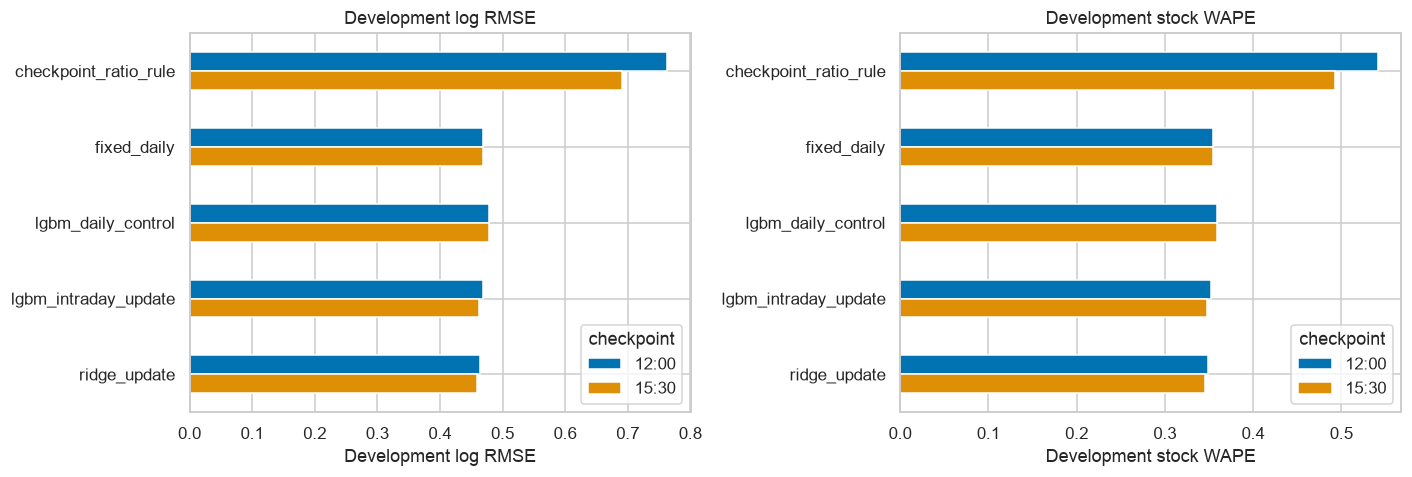

,method,period,metric,noon_minus_1530,ci_lower,ci_upper
0,ridge_update,development,log_mae_delta,0.003419,0.002904,0.003927
1,ridge_update,development,daily_wape_delta,0.002171,0.001521,0.002777
2,ridge_update,confirmation,log_mae_delta,0.007220,0.006473,0.007958
3,ridge_update,confirmation,daily_wape_delta,0.004546,0.003625,0.005477
4,lgbm_intraday_update,development,log_mae_delta,0.004887,0.004245,0.005571
5,lgbm_intraday_update,development,daily_wape_delta,0.003734,0.002969,0.004479
6,lgbm_intraday_update,confirmation,log_mae_delta,0.003332,0.002154,0.004471
7,lgbm_intraday_update,confirmation,daily_wape_delta,0.002370,0.000998,0.003657


LightGBM information gate: 15:30


,reference,rmse_change,worst_annual_rmse_change,wape_change,paired_log_mae_ci_upper,passes
0,fixed_daily,-0.007345,-0.003584,-0.007021,-0.005431,True
1,lgbm_daily_control,-0.016567,-0.014935,-0.011815,-0.012309,True


LightGBM information gate: 12:00


,reference,rmse_change,worst_annual_rmse_change,wape_change,paired_log_mae_ci_upper,passes
0,fixed_daily,-0.000392,0.003503,-0.002231,-0.000571,False
1,lgbm_daily_control,-0.009922,-0.008634,-0.007175,-0.007951,True


In [6]:
comparison=[]
for study,time in [(20,'12:00'),(19,'15:30')]:
    annual=verified[(verified.study.eq(study))&verified['sample'].eq('all_regular_sessions')]
    table=read(study,'intraday_comparison.csv').set_index('candidate')
    development=annual[annual.year.isin(DEV)].groupby('candidate')[['rmse_log','wape','aggregate_bias']].mean()
    confirmation=annual[annual.year.eq(2025)].set_index('candidate')
    for name,row in table.iterrows():
        np.testing.assert_allclose([row.development_rmse_log,row.development_wape,row.development_bias],development.loc[name],atol=1e-12)
        np.testing.assert_allclose([row.confirmation_rmse_log,row.confirmation_wape,row.confirmation_bias],confirmation.loc[name,['rmse_log','wape','aggregate_bias']].to_numpy(float),atol=1e-12)
    table['checkpoint']=time;comparison.append(table.reset_index())
comparison=pd.concat(comparison,ignore_index=True);comparison.to_csv(RUN/'checkpoint_comparison.csv',index=False)
display(comparison.set_index(['checkpoint','candidate']))
fig,axes=plt.subplots(1,2,figsize=(13,4.5))
for ax,metric,title in zip(axes,['development_rmse_log','development_wape'],['Development log RMSE','Development stock WAPE']):
    plotted=comparison.pivot(index='candidate',columns='checkpoint',values=metric)
    plotted.plot.barh(ax=ax);ax.set(title=title,xlabel=title,ylabel='');ax.invert_yaxis()
plt.tight_layout();plt.show()
display(read(20,'paired_checkpoint_time_bootstrap.csv'))
for study in [19,20]:
    table=read(study,'intraday_comparison.csv').set_index('candidate')
    source=annual_sources[study];source=source[source['sample'].eq('all_regular_sessions')&source.test_year.isin(DEV)]
    pivot=source.pivot(index='candidate',columns='test_year',values='rmse_log')
    gate=read(study,'intraday_information_gate.csv')
    for row in gate.itertuples():
        delta=table.loc['lgbm_intraday_update','development_rmse_log']-table.loc[row.reference,'development_rmse_log']
        worst=(pivot.loc['lgbm_intraday_update']-pivot.loc[row.reference]).max()
        wape=table.loc['lgbm_intraday_update','development_wape']-table.loc[row.reference,'development_wape']
        np.testing.assert_allclose([delta,worst,wape],[row.rmse_change,row.worst_annual_rmse_change,row.wape_change],atol=1e-12)
        assert bool(row.passes)==bool(delta<=-.002 and worst<=.002 and wape<=0 and row.paired_log_mae_ci_upper<0)
    print('LightGBM information gate:', '15:30' if study==19 else '12:00');display(gate)

## Matched daily-only ridge control and feature ablations

A second model layer can change a forecast even without receiving today's activity. The matched daily-only ridge keeps the same daily/history inputs, preprocessing, sample rows, penalty grid and target, but excludes all ten current checkpoint inputs. Development log RMSE is **0.47488** for this control versus **0.45995** for full 15:30 ridge. Paired serial-block log-MAE intervals favor the full ridge against both control and fixed daily reference.

The four current-session groups are disjoint: volume, trades, recent activity and price. Add-one experiments begin with daily-only ridge; drop-one experiments begin with the full ridge. Each variant selects its own penalty historically and keeps missing indicators with their source. Volume, trades and recent activity carry useful predictive information. Price inputs add little in this specification. Correlation between groups means their effects need not add up, and these predictive comparisons do not establish causality.

,candidate,rmse_log,wape,aggregate_bias,period
0,fixed_daily,0.469491,0.354676,-0.144684,development
1,ridge_daily_control,0.474878,0.356962,-0.129938,development
2,ridge_update,0.459954,0.345919,-0.118001,development
3,fixed_daily,0.429014,0.328298,-0.090003,confirmation
4,ridge_daily_control,0.426726,0.330393,-0.078790,confirmation
5,ridge_update,0.409157,0.317815,-0.069106,confirmation


,reference,period,block_dates,mean_log_mae_delta,ci_lower,ci_upper
0,fixed_daily,development,5,-0.010020,-0.011870,-0.008637
1,fixed_daily,development,20,-0.010020,-0.012011,-0.008560
2,fixed_daily,confirmation,5,-0.017825,-0.019720,-0.015220
3,fixed_daily,confirmation,20,-0.017825,-0.020562,-0.014475
4,ridge_daily_control,development,5,-0.012902,-0.013981,-0.012017
5,ridge_daily_control,development,20,-0.012902,-0.014109,-0.011993
6,ridge_daily_control,confirmation,5,-0.016024,-0.017169,-0.014688
7,ridge_daily_control,confirmation,20,-0.016024,-0.017722,-0.014431


,candidate,rmse_log,wape,aggregate_bias,period
0,add_price,0.474695,0.357021,-0.130356,development
1,add_recent_activity,0.463362,0.347248,-0.129573,development
2,add_trades,0.462628,0.348187,-0.116432,development
3,add_volume,0.461665,0.346535,-0.127438,development
4,drop_price,0.460058,0.345900,-0.117825,development
5,drop_recent_activity,0.460882,0.346866,-0.118925,development
6,drop_trades,0.460400,0.345539,-0.126215,development
7,drop_volume,0.460601,0.346259,-0.117991,development
8,fixed_daily,0.469491,0.354676,-0.144684,development
9,ridge_daily_control,0.474878,0.356962,-0.129938,development


,source fields
volume,"[cp_cum_volume, cp_cum_dollar_volume, cp_volum..."
trades,"[cp_cum_trade_count, cp_trade_count_surprise20]"
recent_activity,"[cp_recent_30m_volume, cp_recent_30m_volume_sh..."
price,"[cp_vwap, cp_vwap_return_prior_close]"


,period,group,comparison,reference,rmse_log,rmse_log_change,wape_change_pp,bias_change_pp
0,development,volume,add,ridge_daily_control,0.461665,-0.013212,-1.042666,0.250018
1,development,volume,drop,ridge_update,0.460601,0.000647,0.033939,0.000946
2,development,trades,add,ridge_daily_control,0.462628,-0.012250,-0.877481,1.350623
3,development,trades,drop,ridge_update,0.460400,0.000446,-0.038055,-0.821474
4,development,recent_activity,add,ridge_daily_control,0.463362,-0.011516,-0.971350,0.036575
5,development,recent_activity,drop,ridge_update,0.460882,0.000928,0.094664,-0.092468
6,development,price,add,ridge_daily_control,0.474695,-0.000183,0.005948,-0.041800
7,development,price,drop,ridge_update,0.460058,0.000104,-0.001978,0.017566
8,confirmation,volume,add,ridge_daily_control,0.411763,-0.014964,-1.135776,0.465409
9,confirmation,volume,drop,ridge_update,0.409697,0.000540,0.012474,-0.027573


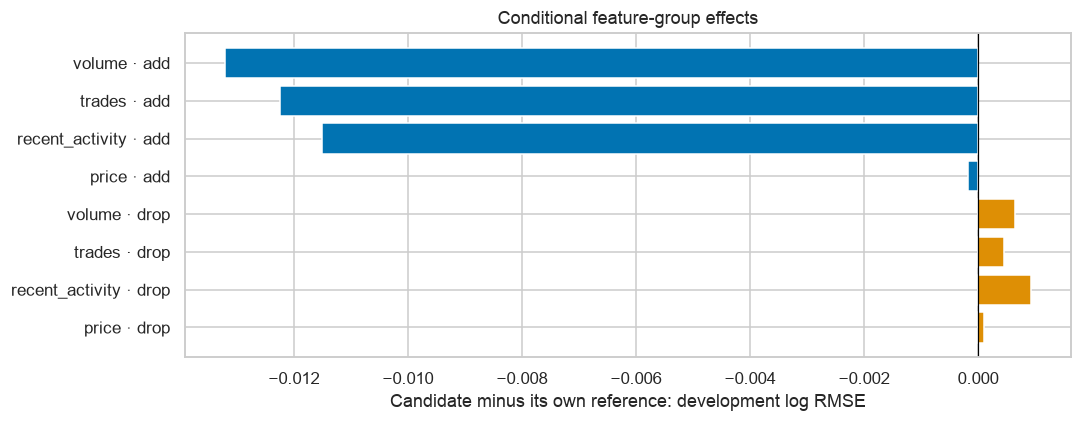

In [7]:
display(read(22,'comparison.csv'));display(read(22,'paired_block_bootstrap.csv'))
ablation=read(23,'comparison.csv');display(ablation)
groups=load_json(SOURCES[23]/'experiment_plan.json')['groups'];display(pd.Series(groups,name='source fields').to_frame())
contrasts=read(23,'group_contrasts.csv');display(contrasts)
fig,ax=plt.subplots(figsize=(10,4))
part=contrasts[contrasts.period.eq('development')]
for kind,rows in part.groupby('comparison'):
    ax.barh(rows['group']+' · '+kind,rows.rmse_log_change,label=kind)
ax.axvline(0,color='black',linewidth=.8);ax.set(xlabel='Candidate minus its own reference: development log RMSE',title='Conditional feature-group effects');ax.invert_yaxis()
plt.tight_layout();plt.show()

## Partial corrections and the adoption decision

Partial corrections interpolate the already bounded full ridge and daily forecasts in log space:

$$\log(1+\hat A_\alpha)=\log(1+D)+\alpha\{\log(1+\hat A_{\mathrm{ridge}})-\log(1+D)\},\quad \alpha\in\{0,0.1,\ldots,1\}.$$

Strength zero returns daily exactly and strength one returns full ridge exactly. No second clipping is applied. Historical validation chooses global or predeclared month-end/low-liquidity strengths; targeted variants keep full ridge outside the target. Fewer than eight cell dates or 500 rows falls back to the global strength. The same historical validation previously chose the ridge penalty, so this is joint tuning rather than a new nested calibration split.

Low-liquidity shrinkage lowers development log RMSE by about 0.00321, but raises WAPE slightly. It therefore fails the source study's strict no-WAPE-worsening condition, as does combined shrinkage. Global shrinkage's gain is too small and its log-MAE interval includes zero. The development-only saved decision retains full ridge. This is a decision under the declared multi-metric rule; it does not mean every partial correction has a higher log-RMSE point estimate.

In [8]:
strengths=read(24,'selected_strengths.csv');display(strengths)
shrinkage=read(24,'comparison.csv');display(shrinkage)
gate=read(24,'development_adoption_gate.csv')
for row in gate.itertuples():
    expected=row.rmse_change<=-.002 and row.wape_change<=0 and row.worst_annual_change<=.002 and row.worst_annual_vs_daily<=.002 and row.wape_vs_daily<=0 and row.paired_ci_upper<0
    assert bool(row.passes)==bool(expected)
assert not gate.passes.any();display(gate)
display(load_json(SOURCES[24]/'development_decision.json'))

,test_year,candidate,cell,alpha,observations,dates,used_global_fallback,validation_start,validation_end
0,2022,global_shrink,global,0.900000,82737,63,False,2021-10-01 00:00:00,2021-12-31 00:00:00
1,2022,month_end_shrink,month_end,0.900000,4028,3,True,2021-10-01 00:00:00,2021-12-31 00:00:00
2,2022,low_liquidity_shrink,low_liquidity,0.700000,24512,63,False,2021-10-01 00:00:00,2021-12-31 00:00:00
3,2022,month_end_liquidity_shrink,month_end_only,0.900000,2788,3,True,2021-10-01 00:00:00,2021-12-31 00:00:00
4,2022,month_end_liquidity_shrink,low_liquidity_only,0.700000,23272,60,False,2021-10-01 00:00:00,2021-12-31 00:00:00
5,2022,month_end_liquidity_shrink,month_end_and_low,0.900000,1240,3,True,2021-10-01 00:00:00,2021-12-31 00:00:00
6,2023,global_shrink,global,0.700000,120000,250,False,2022-01-03 00:00:00,2022-12-30 00:00:00
7,2023,month_end_shrink,month_end,0.400000,5726,12,False,2022-01-03 00:00:00,2022-12-30 00:00:00
8,2023,low_liquidity_shrink,low_liquidity,0.500000,34277,250,False,2022-01-03 00:00:00,2022-12-30 00:00:00
9,2023,month_end_liquidity_shrink,month_end_only,0.400000,4077,12,False,2022-01-03 00:00:00,2022-12-30 00:00:00


,candidate,rmse_log,wape,aggregate_bias,period
0,fixed_daily,0.469491,0.354676,-0.144684,development
1,global_shrink,0.458352,0.345433,-0.125583,development
2,low_liquidity_shrink,0.456747,0.345981,-0.118774,development
3,month_end_liquidity_shrink,0.456957,0.346031,-0.118845,development
4,month_end_shrink,0.459929,0.345861,-0.118201,development
5,ridge_update,0.459954,0.345919,-0.118001,development
6,fixed_daily,0.429014,0.328298,-0.090003,confirmation
7,global_shrink,0.409777,0.316436,-0.074786,confirmation
8,low_liquidity_shrink,0.410782,0.317977,-0.069521,confirmation
9,month_end_liquidity_shrink,0.410856,0.318032,-0.072724,confirmation


,candidate,rmse_change,wape_change,worst_annual_change,worst_annual_vs_daily,wape_vs_daily,paired_ci_upper,passes
0,global_shrink,-0.001602,-0.000486,-0.001299,-0.009231,-0.009242,0.000109,False
1,month_end_shrink,-0.000025,-0.000059,0.000294,-0.007587,-0.008815,0.000085,False
2,low_liquidity_shrink,-0.003207,0.000061,-0.003010,-0.010459,-0.008695,-0.000330,False
3,month_end_liquidity_shrink,-0.002997,0.000112,-0.002795,-0.010460,-0.008644,-0.000190,False


{'selected_candidate': 'ridge_update',
 'decided_before_scoring_2025': True,
 'development_only': True,
 'decision_utc': '2026-11-13T20:23:27.678448+00:00',
 'gate': 'Versus full ridge: development mean log RMSE gain >=0.002, no annual worsening >0.002, no mean WAPE worsening, 20-date paired log-MAE upper CI <0. Versus daily: no annual log RMSE worsening >0.002, no mean WAPE worsening. Pick lowest development RMSE among passers, else retain full.',
 'development_metrics': [{'candidate': 'fixed_daily',
   'rmse_log': 0.4694907439571591,
   'wape': 0.35467575667531087,
   'aggregate_bias': -0.14468375423180754,
   'period': 'development'},
  {'candidate': 'global_shrink',
   'rmse_log': 0.4583515029517911,
   'wape': 0.34543342977749075,
   'aggregate_bias': -0.12558307234285057,
   'period': 'development'},
  {'candidate': 'low_liquidity_shrink',
   'rmse_log': 0.45674731353029346,
   'wape': 0.34598056132036437,
   'aggregate_bias': -0.11877357358363132,
   'period': 'development'},
  

## Robustness and direct uncertainty for the frozen original pairing

The original 15:30 ridge improves development log RMSE in 32 of 36 months, with mixed low-liquidity, large-stock and month-end diagnostics. Actual-volume tail membership is a retrospective error diagnostic, never an available input or a forecast routing rule. Strong overall results can coexist with weak subgroups.

The earliest bootstrap tables concern **mean daily log MAE**, even when headline tables emphasize log RMSE. The later frozen evaluation recomputes log RMSE, WAPE, signed bias and absolute annual bias directly in each replicate. It uses paired 20-session circular blocks within each year, 5,000 replicates, then equal-year aggregation; 5/60-session lengths are sensitivities. Whole stock cross-sections stay together. Absolute annual bias is averaged after taking each year's absolute bias.

The following cell rebuilds overall daily sufficient statistics from the restored forecasts and reproduces the eight primary direct-metric interval rows. Subgroup source intervals are suppressed for fewer than 30 dates or 500 observations in any constituent year. Thousands of stock rows on a few annual events do not supply thousands of independent event dates.

In [9]:
from notebooks.evaluate_frozen_intraday import circular_weights,statistics,COLS
paths=[str(RUN/f'predictions/reconstructed_19_{year}.parquet') for year in YEARS]
con.read_parquet(paths).create_view('restored_1530',replace=True)
daily=con.execute("""SELECT date,year,count(*) n,sum(auction_volume) actual,
    sum(pow(ln(1+fixed_daily)-ln(1+auction_volume),2)) sse_daily,
    sum(pow(ln(1+ridge_update)-ln(1+auction_volume),2)) sse_update,
    sum(abs(fixed_daily-auction_volume)) ae_daily,sum(abs(ridge_update-auction_volume)) ae_update,
    sum(fixed_daily) pred_daily,sum(ridge_update) pred_update
    FROM restored_1530 GROUP BY date,year ORDER BY year,date""").df()
saved_daily=read(25,'daily_sufficient_statistics.csv');saved_daily=saved_daily[saved_daily.dimension.eq('overall')].sort_values(['year','date'])
np.testing.assert_allclose(daily[COLS],saved_daily[COLS],rtol=1e-10,atol=1e-7)
daily.to_csv(RUN/'restored_daily_sufficient_statistics.csv',index=False)
weight_records=read(25,'bootstrap_weight_fingerprints.csv');source_intervals=read(25,'metric_intervals.csv')
interval_checks=[]
for period,years in [('development',DEV),('confirmation',[2025])]:
    points=[];sampled=[]
    for year in years:
        arr=daily[daily.year.eq(year)][COLS].to_numpy(float)
        record=weight_records[weight_records.year.eq(year)&weight_records.block_dates.eq(20)].iloc[0]
        weights=circular_weights(len(arr),20,5000,int(record.seed))
        assert hashlib.sha256(weights.tobytes()).hexdigest()==record.sha256
        points.append(statistics(arr.sum(axis=0)));sampled.append(statistics(weights@arr))
    point=np.mean(points,axis=0);draws=np.mean(sampled,axis=0)
    difference=point[1]-point[0];bounds=np.quantile(draws[:,1]-draws[:,0],[.025,.975],axis=0)
    for j,metric in enumerate(['rmse_log','wape','signed_bias','absolute_annual_bias']):
        expected=source_intervals[source_intervals.period.eq(period)&source_intervals.dimension.eq('overall')&source_intervals.block_dates.eq(20)&source_intervals.metric.eq(metric)].iloc[0]
        np.testing.assert_allclose([difference[j],bounds[0,j],bounds[1,j]],[expected.difference,expected.ci_lower,expected.ci_upper],rtol=1e-8,atol=1e-10)
        interval_checks.append({'period':period,'metric':metric,'difference':difference[j],'lower':bounds[0,j],'upper':bounds[1,j]})
interval_checks=pd.DataFrame(interval_checks);interval_checks.to_csv(RUN/'verified_frozen_primary_intervals.csv',index=False)
display(interval_checks)
display(read(21,'robustness_summary.csv'))
display(source_intervals.groupby(['dimension','status']).size().rename('interval_rows').to_frame())

,period,metric,difference,lower,upper
0,development,rmse_log,-0.009537,-0.011352,-0.007808
1,development,wape,-0.008756,-0.010351,-0.007170
2,development,signed_bias,0.026683,0.020810,0.032804
3,development,absolute_annual_bias,-0.026683,-0.032804,-0.020810
4,confirmation,rmse_log,-0.019857,-0.022868,-0.016090
5,confirmation,wape,-0.010483,-0.014790,-0.006425
6,confirmation,signed_bias,0.020897,0.010626,0.031212
7,confirmation,absolute_annual_bias,-0.020897,-0.031212,-0.010626


,method,period,years,mean_annual_rmse_change,mean_annual_wape_change,months,months_rmse_improved,months_wape_improved
0,ridge_update,development,3,-0.009537,-0.008756,36,32,31
1,ridge_update,confirmation,1,-0.019857,-0.010483,12,12,11
2,lgbm_intraday_update,development,3,-0.007345,-0.007021,36,30,29
3,lgbm_intraday_update,confirmation,1,-0.013420,-0.007080,12,12,11


interval_rows
dimension             status                   
event                 reported                8
                      suppressed             24
history               reported               16
                      suppressed             16
liquidity             reported               24
                      suppressed              8
month_end_x_liquidity reported               24
                      suppressed             40
overall               reported               24
size                  reported               24
                      suppressed              8

## Quarterly versus annual ridge refits

Sixteen quarterly folds validate on the immediately preceding complete quarter, fit on earlier 2021-onward history, and refit before forecasting the next quarter. Daily anchors remain annual. No partial-correction stage is added.

Quarterly ridge improves log RMSE over daily in every evaluated quarter. Its development score is **0.45889**, versus **0.45995** for the original annual ridge. The paired development difference is about −0.00107, with a 20-date-block interval of **[−0.00213, +0.00005]**; WAPE uncertainty also includes zero. It is a useful sensitivity, without a demonstrated qualifying replacement. Samples, windows and forecast bounds change alongside refit frequency, so this comparison does not isolate frequency alone.

These quarterly results are around the original daily anchor. They do not establish quarterly improvement for the tuned daily pairing.

,candidate,rmse_log,wape,aggregate_bias,period
0,annual_ridge,0.459954,0.345919,-0.118001,development
1,fixed_daily,0.469491,0.354676,-0.144684,development
2,quarterly_ridge,0.458885,0.345259,-0.117596,development
3,annual_ridge,0.409157,0.317815,-0.069106,confirmation
4,fixed_daily,0.429014,0.328298,-0.090003,confirmation
5,quarterly_ridge,0.408919,0.316324,-0.070642,confirmation


candidate,annual_ridge,fixed_daily,quarterly_ridge
fold,,,
2022Q1,0.519573,0.525799,0.519573
2022Q2,0.519395,0.524190,0.523890
2022Q3,0.480985,0.489518,0.482157
2022Q4,0.489488,0.499975,0.487885
2023Q1,0.450394,0.457818,0.446693
2023Q2,0.466083,0.474607,0.466680
2023Q3,0.454621,0.463005,0.452595
2023Q4,0.439719,0.449536,0.435763
2024Q1,0.414126,0.421727,0.411606


,period,reference,metric,block_dates,difference,ci_lower,ci_upper
4,development,fixed_daily,rmse_log,20,-0.010606,-0.012352,-0.008860
5,development,fixed_daily,wape,20,-0.009416,-0.011049,-0.007703
6,development,fixed_daily,signed_bias,20,0.027088,0.019516,0.034813
7,development,fixed_daily,absolute_annual_bias,20,-0.027088,-0.034813,-0.019516
12,development,annual_ridge,rmse_log,20,-0.001069,-0.002129,0.000052
13,development,annual_ridge,wape,20,-0.000660,-0.001776,0.000445
14,development,annual_ridge,signed_bias,20,0.000405,-0.004511,0.005465
15,development,annual_ridge,absolute_annual_bias,20,-0.000405,-0.005465,0.004511
20,confirmation,fixed_daily,rmse_log,20,-0.020095,-0.023269,-0.016091
21,confirmation,fixed_daily,wape,20,-0.011973,-0.015885,-0.008105


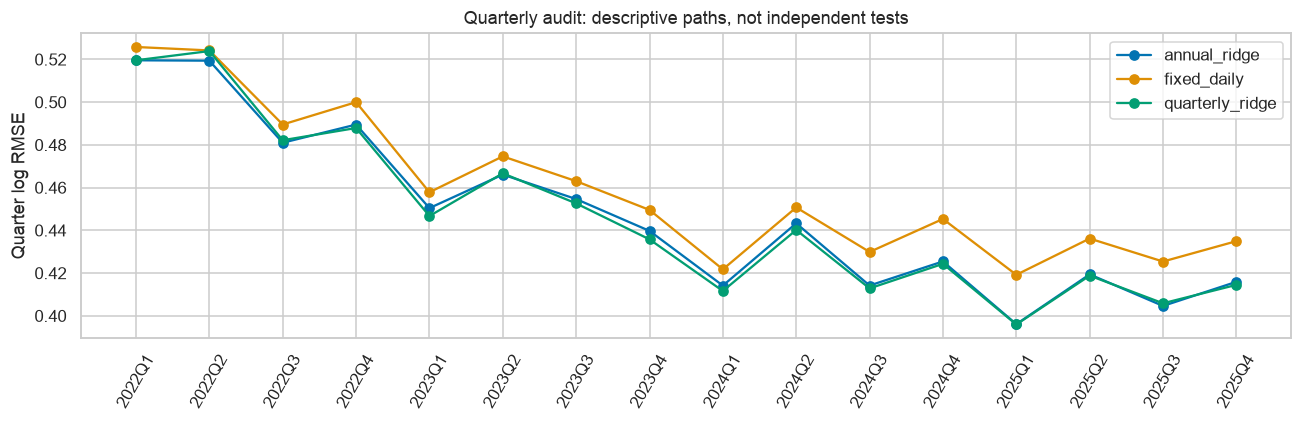

In [10]:
quarterly=read(26,'comparison.csv');display(quarterly)
quarter_metrics=read(26,'quarter_metrics.csv');display(quarter_metrics.pivot(index='fold',columns='candidate',values='rmse_log'))
qintervals=read(26,'metric_intervals.csv');display(qintervals[qintervals.block_dates.eq(20)])
qannual=annual_sources[26];qdev=qannual[qannual.year.isin(DEV)].groupby('candidate')[['rmse_log','wape','aggregate_bias']].mean()
for row in qintervals.itertuples():
    period_years=DEV if row.period=='development' else [2025]
    metrics=qannual[qannual.year.isin(period_years)].copy()
    if row.metric=='absolute_annual_bias':metric='aggregate_bias';metrics[metric]=metrics[metric].abs()
    else:metric='aggregate_bias' if row.metric=='signed_bias' else row.metric
    metrics=metrics.groupby('candidate')[metric].mean()
    np.testing.assert_allclose(metrics['quarterly_ridge']-metrics[row.reference],row.difference,atol=1e-12)
fig,ax=plt.subplots(figsize=(12,4))
for name,part in quarter_metrics.groupby('candidate'):
    ax.plot(part.fold,part.rmse_log,marker='o',label=name)
ax.tick_params(axis='x',rotation=60);ax.set(ylabel='Quarter log RMSE',title='Quarterly audit: descriptive paths, not independent tests');ax.legend();plt.tight_layout();plt.show()

## Daily anchors paired with the same 15:30 ridge procedure

We have three complete anchors: original 58-source LightGBM, tuned 61-source LightGBM, and a fixed 50/50 log-space blend of tuned LightGBM with the neural hybrid. Each anchor receives its own historically fitted ridge correction around its own forecast. This is **not** a swap of daily numbers inside a ridge trained on a different anchor.

Refitted ridges share the original 73-source specification, the same ordered historical samples, caps, cutoff, penalty grid and bounds. The three new daily ratios influence the correction through the anchor forecast; they are not separately appended to ridge inputs. A matched refit of the original anchor separates anchor choice from differences in the saved original ridge's samples.

The source comparison retains all available complete pairings. It does not test every conceivable combination, noon correction on the tuned anchor, or tuned-anchor quarterly refits. The daily neural blend remains a challenger in notebook 09; including it here tests whether a correction changes that assessment.

In [11]:
pair_annual=read(27,'annual_metrics.csv');pair_period=read(27,'period_metrics.csv');pair_intervals=read(27,'paired_intervals.csv')
pair_scores=[]
for year in YEARS:
    progress(f'Verifying saved daily pairings and ridge coefficients {year}')
    frame=con.execute('SELECT * FROM read_parquet(?) WHERE year(date)=? ORDER BY date,permno',[str(A/'matched_predictions.parquet'),year]).df()
    source=con.execute(f'SELECT {projection} FROM read_parquet(?) WHERE year={year} AND NOT is_early_close ORDER BY date,permno',[str(A/'checkpoint_panel.parquet')]).df()
    pd.testing.assert_frame_equal(frame[['date','permno','auction_volume']],source[['date','permno','auction_volume']],check_dtype=False)
    np.testing.assert_array_equal(frame.cp_available,source.cp_available)
    original=con.execute('SELECT fixed_daily,ridge_update FROM read_parquet(?) ORDER BY date,permno',[str(RUN/f'predictions/reconstructed_19_{year}.parquet')]).df()
    np.testing.assert_allclose(frame.original_daily,original.fixed_daily,rtol=1e-12)
    np.testing.assert_allclose(frame.original_ridge_1530,original.ridge_update,rtol=1e-10,atol=1e-7)
    for anchor in ['original','tree','blend']:
        settings=load_json(A/f'{anchor}_ridge_{year}.json')
        assert pd.Timestamp(settings['latest_refit_date'])<source.date.min()
        source['daily_forecast']=frame[f'{anchor}_daily'].to_numpy();source['log_daily_forecast']=np.log1p(source.daily_forecast)
        fitted=correction(source,predict_ridge(transform(source,settings['preprocessor']),np.array(settings['coefficient'])),settings['clip_log'])
        column='original_ridge_1530_matched_refit' if anchor=='original' else f'{anchor}_ridge_1530'
        np.testing.assert_allclose(fitted,frame[column],rtol=1e-9,atol=1e-7)
        stages=['daily','ridge_1530','ridge_1530_matched_refit'] if anchor=='original' else ['daily','ridge_1530']
        for stage in stages:
            column=f'{anchor}_{stage}'
            np.testing.assert_array_equal(frame.loc[~frame.cp_available,column],frame.loc[~frame.cp_available,f'{anchor}_daily'])
            result=scores(frame.auction_volume,frame[column])
            expected=pair_annual[pair_annual.year.eq(year)&pair_annual.anchor.eq(anchor)&pair_annual.stage.eq(stage)].iloc[0]
            for metric,value in result.items():np.testing.assert_allclose(value,expected[metric],rtol=1e-8,atol=1e-9)
            pair_scores.append({'year':year,'anchor':anchor,'stage':stage,**result})
pair_scores=pd.DataFrame(pair_scores);pair_scores.to_csv(RUN/'verified_pairing_scores.csv',index=False)
assert len(pair_scores)==28
for row in pair_period.itertuples():
    years=DEV if row.period=='2022–24' else [2025]
    selected=pair_scores[pair_scores.year.isin(years)&pair_scores.anchor.eq(row.anchor)&pair_scores.stage.eq(row.stage)]
    np.testing.assert_allclose(selected[['rmse_log','wape','aggregate_bias']].mean(),[row.rmse_log,row.wape,row.aggregate_bias],atol=1e-12)
for row in pair_intervals.itertuples():
    # Decompose the known column names without splitting anchor names from underscores ambiguously.
    def point(column):
        anchor,stage=column.split('_',1)
        frame=pair_period[pair_period.period.eq(row.period)&pair_period.anchor.eq(anchor)&pair_period.stage.eq(stage)]
        if row.metric=='absolute_bias':
            years=DEV if row.period=='2022–24' else [2025]
            return pair_scores[pair_scores.year.isin(years)&pair_scores.anchor.eq(anchor)&pair_scores.stage.eq(stage)].aggregate_bias.abs().mean()
        metric='aggregate_bias' if row.metric=='signed_bias' else row.metric
        return frame[metric].item()
    np.testing.assert_allclose(point(row.candidate)-point(row.reference),row.difference,atol=1e-12)
display(pair_period.set_index(['period','anchor','stage']))
display(pair_intervals[pair_intervals.metric.eq('rmse_log')&pair_intervals.reference.isin(['original_ridge_1530_matched_refit','tree_ridge_1530','tree_daily'])])
display(read(27,'daily_refit_audit.csv'))

2026-11-18T16:56:04.373596+00:00 Verifying saved daily pairings and ridge coefficients 2022


2026-11-18T16:56:06.245119+00:00 Verifying saved daily pairings and ridge coefficients 2023


2026-11-18T16:56:07.961714+00:00 Verifying saved daily pairings and ridge coefficients 2024


2026-11-18T16:56:09.625967+00:00 Verifying saved daily pairings and ridge coefficients 2025


rmse_log     wape  aggregate_bias
period  anchor   stage                                                      
2022–24 original daily                     0.469491 0.354676       -0.144684
                 ridge_1530                0.459954 0.345919       -0.118001
                 ridge_1530_matched_refit  0.459120 0.345275       -0.119316
        tree     daily                     0.464074 0.348721       -0.153121
                 ridge_1530                0.454705 0.339832       -0.122369
        blend    daily                     0.462206 0.348611       -0.153722
                 ridge_1530                0.453965 0.340332       -0.122543
2025    original daily                     0.429014 0.328298       -0.090003
                 ridge_1530                0.409157 0.317815       -0.069106
                 ridge_1530_matched_refit  0.408874 0.318115       -0.066228
        tree     daily                     0.421605 0.323135       -0.090114
                 ridge_1530                0.404183 0.314614       -0.058377
        blend    daily                     0.418329 0.319686       -0.108995
                 ridge_1530                0.401556 0.310088       -0.079903

,period,reference,candidate,metric,difference,lower,upper
8,2022–24,tree_daily,tree_ridge_1530,rmse_log,-0.009368,-0.010917,-0.007808
12,2025,tree_daily,tree_ridge_1530,rmse_log,-0.017421,-0.019405,-0.015167
40,2022–24,original_ridge_1530_matched_refit,tree_ridge_1530,rmse_log,-0.004414,-0.006460,-0.002468
44,2025,original_ridge_1530_matched_refit,tree_ridge_1530,rmse_log,-0.004690,-0.007900,-0.002317
48,2022–24,original_ridge_1530_matched_refit,blend_ridge_1530,rmse_log,-0.005155,-0.008469,-0.001507
52,2025,original_ridge_1530_matched_refit,blend_ridge_1530,rmse_log,-0.007318,-0.015273,-0.001057
56,2022–24,tree_ridge_1530,blend_ridge_1530,rmse_log,-0.000740,-0.003435,0.003002
60,2025,tree_ridge_1530,blend_ridge_1530,rmse_log,-0.002627,-0.007730,0.002064


,year,anchor,observations,published_log_rmse,refit_log_rmse,published_wape,refit_wape
0,2022,tree,328634,0.502508,0.504607,0.359755,0.359694
1,2023,tree,318679,0.454688,0.454301,0.346040,0.345341
2,2024,tree,316212,0.433516,0.433161,0.340617,0.340732
3,2025,tree,307853,0.424170,0.422244,0.324364,0.323766
4,2022,blend,328634,0.503649,0.504356,0.361507,0.361561
5,2023,blend,318679,0.455077,0.451710,0.344901,0.344467
6,2024,blend,316212,0.431165,0.430288,0.338999,0.339400
7,2025,blend,307853,0.418392,0.418890,0.319738,0.320315


The **tuned daily plus ridge** pairing scores about **0.45471** development log RMSE and **33.98% WAPE**. Its own daily anchor scores about 0.46407, so the correction improves log RMSE by about 0.00937. Relative to the original daily plus matched ridge refit, it improves about 0.00441, with a paired 20-session-block log-RMSE interval of approximately **[−0.00646, −0.00247]**.

The neural-blend pairing scores about 0.45396, only 0.00074 better than the tuned pairing. Its interval **[−0.00344, +0.00300]** includes zero, WAPE is about 0.05 percentage points worse, and it adds a neural forecasting layer. Its lower 2025 point score does not settle development selection. The tuned pairing remains the preferred main research candidate.

These locally refitted anchors differ slightly from their published whole-universe daily scores. The pairing's regular-session universe also differs from notebook 09's daily universe. The daily-refit audit above distinguishes these differences. Pairing intervals condition on the written forecasts and omit complete daily/intraday refitting and accumulated selection uncertainty.

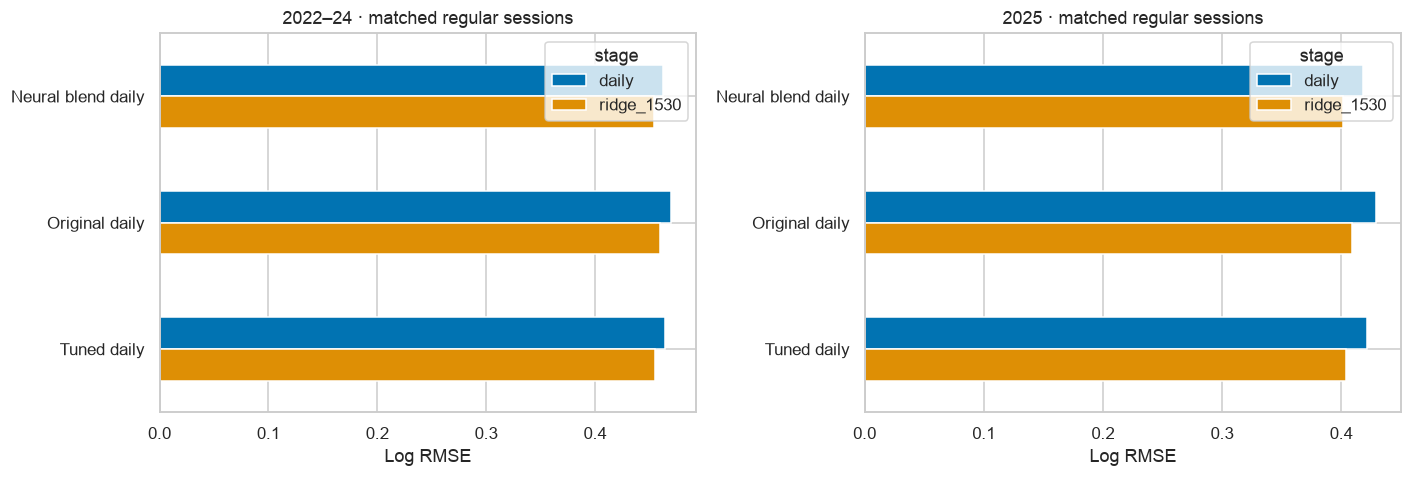

In [12]:
labels={'original':'Original daily','tree':'Tuned daily','blend':'Neural blend daily'}
fig,axes=plt.subplots(1,2,figsize=(13,4.5))
for ax,period in zip(axes,['2022–24','2025']):
    part=pair_period[pair_period.period.eq(period)]
    pivot=part[part.stage.isin(['daily','ridge_1530'])].pivot(index='anchor',columns='stage',values='rmse_log').rename(index=labels)
    pivot.plot.barh(ax=ax);ax.set(title=period+' · matched regular sessions',xlabel='Log RMSE',ylabel='');ax.invert_yaxis()
plt.tight_layout();plt.show()

## Fresh 2022 worked ridge fit

This executable example repeats the **matched original-anchor** ridge procedure for 2022: January–September 2021 tuning, Q4 validation, seven penalties and a final 2021 refit. It uses ordered one-thread reservoir samples with the pairing study's caps and seeds, checks the sample-key fingerprints, saves its fitted preprocessor and coefficients, and compares the resulting forecast with the saved matched pairing.

This checks fitting as well as prediction application for one historical fold. It is separate from the complete four-year saved-model reconstructions above. New fitting occurs only if the complete worked-fit cache is absent; cached runs reconstruct the worked forecast again.

In [13]:
from threadpoolctl import threadpool_limits
FRESH=RUN/'fresh_ridge_2022';fresh_settings=FRESH/'fit.json'
required=[fresh_settings,FRESH/'coefficient.npy',FRESH/'validation.csv',FRESH/'sample_manifest.csv']
if all(path.is_file() for path in required):
    progress('Using complete fresh-2022 ridge cache; reconstructing its forecast below')
else:
    progress('Fresh 2022 matched-original ridge: historical tuning and final refit')
    con.execute('SET threads=1')
    def historical(start,end,cap,seed):
        return con.execute(f"""SELECT {projection} FROM (
            SELECT {projection} FROM read_parquet(?) WHERE date>=DATE '{start}' AND date<DATE '{end}'
              AND NOT is_early_close AND cp_available ORDER BY date,permno
            ) USING SAMPLE {cap} ROWS (reservoir,{seed}) ORDER BY date,permno""",[str(A/'checkpoint_panel.parquet')]).df()
    train=historical('2021-01-01','2021-10-01',250000,intraday.SEED+2022)
    validation=historical('2021-10-01','2022-01-01',120000,intraday.SEED+100+2022)
    refit=historical('2021-01-01','2022-01-01',350000,intraday.SEED+200+2022)
    con.execute('SET threads=4')
    assert train.date.max()<validation.date.min()<=validation.date.max()<pd.Timestamp('2022-01-01')
    source_manifest=read(27,'ridge_sample_manifest.csv');manifest=[]
    for role,frame in [('tune',train),('validation',validation),('refit',refit)]:
        fingerprint=hashlib.sha256(pd.util.hash_pandas_object(frame[['date','permno']],index=False).to_numpy().tobytes()).hexdigest()
        expected=source_manifest[source_manifest.year.eq(2022)&source_manifest['sample'].eq(role)].iloc[0]
        assert fingerprint==expected.key_hash and len(frame)==expected.rows
        manifest.append({'sample':role,'rows':len(frame),'first_date':str(frame.date.min()),'last_date':str(frame.date.max()),'key_hash':fingerprint})
    prep=load_json(SOURCES[19]/'models/preprocessor_2022.json');feature_types=types(prep)
    xt,tune_prep=fit_preprocessor(train,*feature_types);xv=transform(validation,tune_prep)
    target=train.log1p_auction_volume.to_numpy()-train.log_daily_forecast.to_numpy()
    bounds=np.quantile(train.log1p_auction_volume,[.001,.999]);trials=[]
    with threadpool_limits(limits=4):
        for strength in [1e-7,1e-6,1e-5,1e-4,1e-3,1e-2,1e-1]:
            coefficient=fit_ridge(xt,target,strength)
            prediction=correction(validation,predict_ridge(xv,coefficient),bounds)
            trials.append({'strength':strength,'validation_log_rmse':scores(validation.auction_volume,prediction)['rmse_log']})
        best=min(trials,key=lambda row:row['validation_log_rmse'])
        del xt,xv,train,validation;gc.collect()
        xr,prep=fit_preprocessor(refit,*feature_types)
        coefficient=fit_ridge(xr,(refit.log1p_auction_volume-refit.log_daily_forecast).to_numpy(),best['strength'])
    settings={'preprocessor':prep,'coefficient':coefficient.tolist(),'clip_log':np.quantile(refit.log1p_auction_volume,[.001,.999]).tolist(),
              'strength':best['strength'],'latest_refit_date':str(refit.date.max())}
    np.save(FRESH/'coefficient.npy',coefficient);pd.DataFrame(trials).to_csv(FRESH/'validation.csv',index=False)
    pd.DataFrame(manifest).to_csv(FRESH/'sample_manifest.csv',index=False)
    fresh_settings.write_text(json.dumps(settings,indent=2));del xr,refit;gc.collect()
settings=load_json(fresh_settings);historical_settings=load_json(A/'original_ridge_2022.json')
assert settings['strength']==historical_settings['strength']
np.testing.assert_allclose(settings['coefficient'],historical_settings['coefficient'],rtol=1e-8,atol=1e-8)
test=con.execute(f'SELECT {projection} FROM read_parquet(?) WHERE year=2022 AND NOT is_early_close ORDER BY date,permno',[str(A/'checkpoint_panel.parquet')]).df()
prediction=correction(test,predict_ridge(transform(test,settings['preprocessor']),np.load(FRESH/'coefficient.npy')),settings['clip_log'])
reference=con.execute('SELECT original_ridge_1530_matched_refit FROM read_parquet(?) WHERE year(date)=2022 ORDER BY date,permno',[str(A/'matched_predictions.parquet')]).df().iloc[:,0]
np.testing.assert_allclose(prediction,reference,rtol=1e-8,atol=1e-6)
worked_result=scores(test.auction_volume,prediction)
worked_result.update({'year':2022,'strength':settings['strength'],'max_forecast_difference':float(np.max(np.abs(prediction-reference)))})
(FRESH/'verification.json').write_text(json.dumps(worked_result,indent=2))
display(pd.read_csv(FRESH/'sample_manifest.csv'));display(pd.read_csv(FRESH/'validation.csv'))
display(pd.Series(worked_result,name='fresh worked result').to_frame())
del test,prediction;gc.collect()

2026-11-18T16:56:11.377219+00:00 Using complete fresh-2022 ridge cache; reconstructing its forecast below


,sample,rows,first_date,last_date,key_hash
0,tune,237477,2021-01-04 00:00:00,2021-09-30 00:00:00,05902e0a821bcd491a3e883c03c76765a860bafddf44a6...
1,validation,82737,2021-10-01 00:00:00,2021-12-31 00:00:00,2eaae25f793397dd940a9be98fde3d6da805e1cf5be833...
2,refit,320214,2021-01-04 00:00:00,2021-12-31 00:00:00,bbb0200db24069b943a0a7acab8fa735fa7b232ecee023...


,strength,validation_log_rmse
0,0.000000,0.560657
1,0.000001,0.560655
2,0.000010,0.560633
3,0.000100,0.560566
4,0.001000,0.560373
5,0.010000,0.561061
6,0.100000,0.563257


,fresh worked result
observations,"327,355.000000"
rmse_log,0.502538
wape,0.360137
aggregate_bias,-0.122268
year,"2,022.000000"
strength,0.001000
max_forecast_difference,0.000000


13366

## What remains unresolved

The original-anchor subgroup audits identify low-liquidity, large-stock and month-end weaknesses. Their behavior cannot be assumed unchanged after adopting the tuned anchor. A matched control, ablation, shrinkage or quarterly extension on the tuned pairing is additional work; none is promoted by adding improvements from separate studies.

The original source availability audit found no complete post-2025 forward period in the local files it inspected. This notebook scores only the same historical 2022–2025 years. Repeatedly inspecting or refitting those years cannot make them an untouched holdout. The conditional bootstrap intervals omit full refitting and accumulated research-selection uncertainty; subgroup intervals are exploratory and unadjusted for multiple comparisons.

For the next research step, sequential measurements could update a latent daily auction state. Notebook 11 will compare simple regularised multi-time corrections with dynamic regression and Kalman variants, using prior-only fit/calibration windows and the same time-availability rules. A stronger model must show incremental value over the existing tuned daily plus 15:30 ridge pairing, with a clearly matched evaluation.

## Checkpoint 6 decision

| Forecast role | Retained research candidate | Evidence |
| --- | --- | --- |
| Before intraday observations | Tuned 61-source daily LightGBM | Daily decision in notebook 09 |
| Optional early update | Noon ridge around original daily anchor | Modest earlier gain; tuned-anchor noon pairing is untested |
| Main late update | Tuned daily LightGBM + annual 15:30 ridge | Matched development improvement over its daily anchor and original matched pairing |
| Neural daily blend + ridge | Keep as challenger | Small uncertain development gain, slightly worse WAPE and added complexity |
| Partial corrections | Keep as diagnostics/challengers | No tested variant passes every saved adoption condition |
| Quarterly ridge | Keep as sensitivity | Small original-anchor gain with development intervals spanning zero |

The ratio rule and tested intraday LightGBM do not displace ridge in these comparisons. Controls support incremental current-session information within the original model families. The preferred tuned pairing is a retrospective research conclusion; forward performance remains unmeasured.

**Stop for Checkpoint 6 review here.** Notebook 11 begins after approval.

In [14]:
# Reconcile saved development/confirmation summaries for the ridge variants.
summary_checks=[]
for study in [22,23,24,26]:
    saved=read(study,'comparison.csv')
    for row in saved.itertuples():
        years=DEV if row.period=='development' else [2025]
        selected=verified[verified.study.eq(study)&verified.year.isin(years)&verified.candidate.eq(row.candidate)]
        assert selected.year.nunique()==len(years)
        np.testing.assert_allclose(selected[['rmse_log','wape','aggregate_bias']].mean(),[row.rmse_log,row.wape,row.aggregate_bias],atol=1e-12)
        summary_checks.append({'study':study,'candidate':row.candidate,'period':row.period,'passed':True})
summary_checks=pd.DataFrame(summary_checks);summary_checks.to_csv(RUN/'summary_arithmetic_checks.csv',index=False)
# Record original check tables as historical evidence, separate from new checks here.
historical_checks=[]
for study in range(19,27):
    frame=read(study,'validation_checks.csv');assert frame.passed.all()
    historical_checks.append({'study':study,'source_checks':len(frame),'source_passed':True})
display(pd.DataFrame(historical_checks))
inputs.update([PANEL,A/'checkpoint_panel.parquet',A/'matched_predictions.parquet'])
inputs.update((ROOT/'blackrock_data/stock_intraday/trade_checkpoints').glob('year=*/*.parquet'))
manifest=pd.DataFrame([{'path':str(p.relative_to(ROOT)),'bytes':p.stat().st_size,'sha256':sha(p)} for p in sorted(inputs)])
manifest.to_csv(RUN/'source_manifest.csv',index=False)
verification={'checkpoint':6,'evaluation_years':YEARS,'regular_session_stock_days':1260168,
    'reconstructed_annual_score_rows':len(verified),'pairing_annual_score_rows':len(pair_scores),
    'independent_history_rows':int(history_checks.rows.sum()),'primary_bootstrap_interval_rows':len(interval_checks),
    'summary_arithmetic_checks':len(summary_checks),'fresh_ridge_year':2022,'fresh_ridge_sample_fingerprints_match':True,
    'selected_pairing':'tuned daily LightGBM + annual 15:30 ridge',
    'completed_utc':datetime.now(timezone.utc).isoformat()}
(RUN/'verification.json').write_text(json.dumps(verification,indent=2));display(pd.Series(verification,name='new notebook verification').to_frame())
con.close();work.cleanup()

,study,source_checks,source_passed
0,19,124,True
1,20,124,True
2,21,19,True
3,22,60,True
4,23,179,True
5,24,152,True
6,25,94,True
7,26,178,True


,new notebook verification
checkpoint,6
evaluation_years,"[2022, 2023, 2024, 2025]"
regular_session_stock_days,1260168
reconstructed_annual_score_rows,172
pairing_annual_score_rows,28
independent_history_rows,32570
primary_bootstrap_interval_rows,8
summary_arithmetic_checks,46
fresh_ridge_year,2022
fresh_ridge_sample_fingerprints_match,True


## Source map

- [Original 15:30 study](../outputs/experiments/19_intraday_1530/README.md), [noon study](../outputs/experiments/20_intraday_noon/README.md) and [robustness audit](../outputs/experiments/21_intraday_robustness/README.md).
- [Daily-only ridge](../outputs/experiments/22_intraday_ridge_control/README.md), [feature ablation](../outputs/experiments/23_intraday_feature_ablation/README.md), [partial corrections](../outputs/experiments/24_intraday_shrinkage/README.md).
- [Frozen evaluation](../outputs/experiments/25_frozen_intraday_evaluation/README.md), [quarterly refits](../outputs/experiments/26_quarterly_intraday_audit/README.md), [daily pairings](../outputs/experiments/27_intraday_anchor_comparison/README.md).
- Implementations: [shared checkpoint query and original correction](../notebooks/build_intraday_1530_update.py), [corrected noon pipeline](../notebooks/build_intraday_noon_update.py), [anchor comparison](../notebooks/compare_intraday_anchors.py).
- [New audit artifacts](../outputs/experiments/32_intraday_master_audit/) and [daily summary](09_daily_model_results_and_decision.ipynb).

Saved inference tables are labelled as such; the original frozen pairing's primary metric intervals are recomputed here. Annual forecasting scores are checked from reconstructed or written predictions. The fresh fitting example covers 2022 only.